# Solving Pendulum Motion with Missing Data using Parameter Estimation

**APOAI2025 Mock Competition Question 4**

For this question, I use the recorded time and pendulum angle to estimate the rope length, air resistance, external force, the time when that force starts as well as the next time the angle becomes zero after recording ends while using the supplied differential equation to connect the two visible parts of the motion.


# 1. What I need to find

I have measurements from before and after the sensor stopped recording but because a downward force started somewhere during that gap, I need to find values that explain both parts of the motion and the change between them. Use table as reference below:

| Output | Meaning |
| --- | --- |
| `l` | Length of the rope |
| `miu` | Strength of the air resistance |
| `F` | Strength of the added downward force |
| `t_Fput` | Time when that force started |
| `t_nextzerotheta` | Next time the pendulum passes straight down after recording ends |

I use physics-based regression for this, meaning that the pendulum equation gives me a rule for calculating the motion, while PyTorch adjusts the unknown numbers inside that rule to bring the calculated angles closer to the recorded ones. Once I have a fitted equation, I can use it to calculate the missing motion and continue beyond the final measurement to find the requested crossing time.


In [3]:
from pathlib import Path
from time import perf_counter

NOTEBOOK_START = perf_counter()


def find_question_folder(name, marker):
    """Find the question folder without using a computer-specific path."""
    cwd = Path.cwd().resolve()

    for base in (cwd, *cwd.parents):
        candidates = [base] if base.name == name else []
        candidates += [base / name, base / 'ICAIC_Outputs' / name]

        for folder in candidates:
            if (folder / marker).exists():
                return folder.resolve()

    if (cwd / marker).exists():
        return cwd

    raise FileNotFoundError(
        f'Cannot find {name}/{marker} from {cwd}. '
        'Keep the supplied data inside its question folder.'
    )

In [4]:
import os
import tempfile
from types import SimpleNamespace

os.environ.setdefault(
    'MPLCONFIGDIR',
    str(Path(tempfile.gettempdir()) / 'icaic_q4_mpl'),
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import Markdown, display

torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)
torch.use_deterministic_algorithms(True)

settings = SimpleNamespace(starts=4, max_iter=100)

PART_FOLDER = find_question_folder(
    'Question4', 'pendulum_train.csv'
)
DATA_DIR = PART_FOLDER

hidden_data_dir = os.environ.get('DATA_PATH')
OUTPUT_DIR = Path.cwd() if hidden_data_dir else PART_FOLDER
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

INPUT_FILENAMES = {
    'train': 'pendulum_train.csv',
    'A': 'pendulum_testA.csv',
    'B': 'pendulum_testB.csv',
}

OUTPUT_FILENAMES = {
    'train': 'submission_train.csv',
    'A': 'submissionA.csv',
    'B': 'submissionB.csv',
}

input_paths = {}

for name, filename in INPUT_FILENAMES.items():
    folders = (
        [Path(hidden_data_dir)]
        if hidden_data_dir and name != 'train'
        else [DATA_DIR, DATA_DIR / 'data']
    )

    input_paths[name] = next(
        (
            folder / filename
            for folder in folders
            if (folder / filename).is_file()
        ),
        None,
    )

    if hidden_data_dir and name != 'train' and input_paths[name] is None:
        raise FileNotFoundError(
            f'The supplied hidden dataset was not found: {filename}'
        )

print('Training folder:', DATA_DIR)
print('Output folder:', OUTPUT_DIR)

for name, path in input_paths.items():
    print(f'{name}: {path if path is not None else "not supplied locally"}')

Training folder: /Users/davidfrancisco/Documents/ICAIC_Outputs/Question4
Output folder: /Users/davidfrancisco/Documents/ICAIC_Outputs/Question4
train: /Users/davidfrancisco/Documents/ICAIC_Outputs/Question4/pendulum_train.csv
A: not supplied locally
B: not supplied locally


# 2. Read the measurements

I then started by looking at the timestamps because they tell me where the information is missing and treating the rows as equally spaced without checking them would hide the interruption that is central to this problem. In the supplied file, there are 734 observations with the first recorded section ending at about 3.003 seconds and the second beginning at about 7.012 seconds, so those two times give me the interval in which to search for the force starting time.

I sort the observations and check that the time and angle columns contain usable numbers which includes whether the same timestamp has been recorded more than once with conflicting angles. These checks let me establish which values are actual measurements before I begin estimating anything and I keep the gap empty at this stage because the angles inside it will come from the fitted model later.


In [5]:
def prepare_data(frame):
    frame = frame.copy()
    frame.columns = [str(c).strip().lstrip('\ufeff') for c in frame.columns]
    if not {'t', 'theta'}.issubset(frame.columns):
        raise ValueError('The input CSV must contain t and theta columns.')
    frame = frame[['t', 'theta']].apply(pd.to_numeric, errors='raise')
    missing = int(frame['theta'].isna().sum())
    if frame['t'].isna().any():
        raise ValueError('A row has a missing timestamp.')
    frame = frame.dropna(subset=['theta']).sort_values('t')
    if not np.isfinite(frame.to_numpy()).all() or (frame['t'] < 0).any():
        raise ValueError('Recorded values must be finite, with t >= 0.')
    if frame.groupby('t')['theta'].nunique().gt(1).any():
        raise ValueError('Conflicting angles were recorded at the same time.')
    duplicates = int(frame.duplicated('t').sum())
    frame = frame.drop_duplicates('t').reset_index(drop=True)
    if len(frame) < 20:
        raise ValueError('I need at least ten recorded points on each side of the gap.')
    t, theta = frame.to_numpy().T
    differences = np.diff(t)
    typical_step = float(np.median(differences))
    large_gaps = np.flatnonzero((differences >= 1 - 1e-8)
                               & (differences > 3 * typical_step))
    if len(large_gaps) != 1:
        raise ValueError('I expected one interruption of at least one second, '
                         'clearly larger than the normal sampling interval.')
    split = int(large_gaps[0] + 1)
    if min(split, len(t) - split) < 10:
        raise ValueError('There are fewer than ten observations on one side of the gap.')
    return {'frame': frame, 't': t, 'theta': theta, 'split': split,
            'gap': (float(t[split - 1]), float(t[split])),
            'typical_step': typical_step, 'missing_rows': missing,
            'duplicate_rows': duplicates}


if input_paths['train'] is None:
    raise FileNotFoundError('Place pendulum_train.csv inside the Question4 folder.')
training_frame = pd.read_csv(input_paths['train'])
training_data = prepare_data(training_frame)
display(training_data['frame'].head())
print('Recorded observations:', len(training_data['t']))
print('Sensor gap:', training_data['gap'])
print('Recording ends at:', training_data['t'][-1], 'seconds')


,t,theta
0,0.000000,1.050000
1,0.015015,1.049805
2,0.030030,1.049222
3,0.045045,1.048253
4,0.060060,1.046903


Recorded observations: 734
Sensor gap: (3.003003003003003, 7.012012012012012)
Recording ends at: 15.0 seconds


# 3. Use the pendulum equation

I use the differential equation that is already supplied in the problem because it connects the angle I can observe with the speed and acceleration that describe how the pendulum is moving. Here, $\theta'(t)$ means how quickly the angle changes, $\theta''(t)$ means how quickly that speed changes, $\alpha$ controls the slowing effect of air resistance, and $\beta$ controls the pull back towards the middle:

$$\theta''(t)=-\alpha\theta'(t)-\beta\sin(\theta(t)).$$

I also use $\beta_1$ before the force begins and $\beta_2$ afterwards since the added downward force changes the pull towards the middle while the air resistance coefficient stays the same. At the change, I keep the current angle and speed continuous, because applying this force changes the acceleration without instantly shifting the ball's position or giving it a sudden change in speed.

I also keep the initial speed at zero as stated in the problem and retain the full sine term when calculating the motion. Once I have fitted the coefficients, I convert them into the requested physical values using the given mass of one and gravity of 9.8:

$$l=\frac{9.8}{\beta_1},\qquad \mu=\alpha,\qquad F=l(\beta_2-\beta_1).$$


# 4. Fit the unknown parameters

I first estimate starting values from small groups of nearby measurements on each side of the gap and then I use PyTorch's L-BFGS optimizer to adjust the parameters by comparing simulated angles with the recorded angles directly. Afterwards, I try several force starting times inside the gap because one starting guess can lead to a poorer fit and I scale the errors from each recorded section by its angle size so the smaller later swings still contribute to the fitting. I calculate the motion with fourth-order Runge–Kutta integration, and the gradient helper passes the effect of changing each parameter back to PyTorch so the optimizer can improve its estimates.

In [6]:
def local_derivatives(t, theta):
    width = min(11, len(t) if len(t) % 2 else len(t) - 1)
    half = width // 2
    velocities, accelerations, angles = [], [], []
    for i in range(half, len(t) - half):
        x = t[i - half:i + half + 1] - t[i]
        scale = np.max(np.abs(x))
        coefficients = np.polynomial.polynomial.polyfit(
            x / scale, theta[i - half:i + half + 1], 4)
        velocities.append(coefficients[1] / scale)
        accelerations.append(2 * coefficients[2] / scale**2)
        angles.append(theta[i])
    return np.array(velocities), np.array(accelerations), np.array(angles)


def initial_parameters(data):
    rows, targets = [], []
    split = data['split']
    for segment, selection in enumerate((slice(None, split), slice(split, None))):
        t, theta = data['t'][selection], data['theta'][selection]
        velocity, acceleration, angle = local_derivatives(t, theta)
        design = np.zeros((len(angle), 3))
        design[:, 0] = -velocity
        design[:, 1 + segment] = -np.sin(angle)
        scale = max(float(np.max(np.abs(theta))), 1e-4)
        rows.append(design / scale)
        targets.append(acceleration / scale)
    x = torch.tensor(np.vstack(rows), dtype=torch.float64)
    y = torch.tensor(np.concatenate(targets), dtype=torch.float64)
    coefficients = torch.linalg.lstsq(x, y).solution.numpy()
    alpha = max(float(coefficients[0]), 1e-3)
    beta1 = max(float(coefficients[1]), 1e-2)
    beta2 = max(float(coefficients[2]), beta1 + 1e-2)
    theta0 = float(np.clip(data['theta'][0], 1e-3, np.pi / 2 - 1e-3))
    return np.array([alpha, beta1, beta2, theta0, np.mean(data['gap'])])


### Calculate how the pendulum moves

I use `integrate_motion` to calculate the pendulum's angle and speed at each requested time which starts from its initial angle and zero speed and then moving forward in small steps using the differential equation.

I use RK4, which combines four estimates of how the motion changes to calculate each next step more accurately and then when the calculation reaches the estimated force starting time, I switch from `beta1` to `beta2` while keeping the current angle and speed unchanged because the added force changes how the pendulum accelerates rather than instantly changing its position or speed.

In [7]:
def integrate_motion(parameters, times, max_step=0.02, with_jacobian=False):
    alpha, beta1, beta2, theta0, force_time = np.asarray(parameters, dtype=float)
    times = np.asarray(times, dtype=float)
    if times.ndim != 1 or len(times) == 0 or np.any(np.diff(times) < 0) or times[0] < 0:
        raise ValueError('Prediction times must be nonnegative and sorted.')
    if not np.isfinite(parameters).all() or min(alpha, beta1, beta2) <= 0 or force_time < 0:
        raise ValueError('The physical coefficients must be finite and positive.')
    step_limit = min(max_step, 0.15 / np.sqrt(max(beta1, beta2)), 0.15 / alpha)
    state = np.zeros(12 if with_jacobian else 2)
    state[0] = theta0
    if with_jacobian:
        state[2:].reshape(2, 5)[0, 3] = 1.0

    def rhs(z, beta, beta_column):
        theta, omega = z[:2]
        result = np.empty_like(z)
        result[:2] = (omega, -alpha * omega - beta * np.sin(theta))
        if with_jacobian:
            sensitivity = z[2:].reshape(2, 5)
            derivative = result[2:].reshape(2, 5)
            derivative[0] = sensitivity[1]
            derivative[1] = -beta * np.cos(theta) * sensitivity[0] - alpha * sensitivity[1]
            derivative[1, 0] -= omega
            derivative[1, beta_column] -= np.sin(theta)
        return result

    def advance(z, start, end, beta, beta_column):
        count = max(1, int(np.ceil((end - start) / step_limit)))
        h = (end - start) / count
        for _ in range(count):
            k1 = rhs(z, beta, beta_column)
            k2 = rhs(z + h * k1 / 2, beta, beta_column)
            k3 = rhs(z + h * k2 / 2, beta, beta_column)
            k4 = rhs(z + h * k3, beta, beta_column)
            z = z + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        return z

    states, jacobians = [], []
    current, switched = 0.0, False
    for target in times:
        if not switched and target >= force_time:
            state = advance(state, current, force_time, beta1, 1)
            if with_jacobian:
                # Moving the switch changes acceleration, while theta and omega stay continuous.
                state[2:].reshape(2, 5)[1, 4] += (beta2 - beta1) * np.sin(state[0])
            current, switched = force_time, True
        beta, column = (beta2, 2) if switched else (beta1, 1)
        state = advance(state, current, float(target), beta, column)
        current = float(target)
        states.append(state[:2].copy())
        if with_jacobian:
            jacobians.append(state[2:].reshape(2, 5).copy())
    states = np.stack(states)
    return (states, np.stack(jacobians)) if with_jacobian else states


### Build the parameter model

I use `PendulumModel` to store the unknown parameters that PyTorch will adjust while applying transformations that keep the damping positive, make the added force increase the pull towards the middle, and keep the force starting time inside the sensor gap.

Also, I use `ODEAngles` to connect the motion simulation to PyTorch because the simulation uses NumPy and needs a way to pass its derivatives back to the optimizer. Its `forward` method calculates the predicted angles and saves how each parameter affects them while its `backward` method uses that information to calculate how changing the parameters would affect the fitting error.

In [8]:
class ODEAngles(torch.autograd.Function):
    @staticmethod
    def forward(ctx, parameters, times, max_step):
        states, jacobian = integrate_motion(parameters.detach().numpy(),
                                           times.detach().numpy(), max_step, True)
        ctx.save_for_backward(torch.from_numpy(jacobian[:, 0, :]))
        return torch.from_numpy(states[:, 0])

    @staticmethod
    def backward(ctx, output_gradient):
        (jacobian,) = ctx.saved_tensors
        return jacobian.T @ output_gradient, None, None


class PendulumModel(nn.Module):
    def __init__(self, initial, gap):
        super().__init__()
        self.gap = gap
        positive = np.array([initial[0], initial[1], initial[2] - initial[1]])
        # Inverse softplus gives a raw parameter with the desired positive starting value.
        raw_positive = positive + np.log(-np.expm1(-positive))
        ratios = np.clip([initial[3] / (np.pi / 2),
                          (initial[4] - gap[0]) / (gap[1] - gap[0])], 1e-5, 1 - 1e-5)
        raw = np.r_[raw_positive, np.log(ratios / (1 - ratios))]
        self.raw = nn.Parameter(torch.tensor(raw, dtype=torch.float64))

    def physical_parameters(self):
        alpha, beta1, change = F.softplus(self.raw[:3]) + 1e-8
        theta0 = (np.pi / 2) * torch.sigmoid(self.raw[3])
        force_time = self.gap[0] + (self.gap[1] - self.gap[0]) * torch.sigmoid(self.raw[4])
        return torch.stack((alpha, beta1, beta1 + change, theta0, force_time))

    def forward(self, times, max_step=0.02):
        return ODEAngles.apply(self.physical_parameters(), times, max_step)


### Fit the model to the recorded angles

I use `fitting_arrays` to select up to 500 evenly spread observations from each recorded section then scale their errors according to the size of the angles in that section so that the smaller swings after the interruption still influence the fit.

First, I decided to test 33 possible force starting times inside the gap and choose four separated starting guesses because starting from only one guess could lead the optimizer towards a poorer solution as explained earlier. Also, to adjust the model parameters and reduce the weighted square difference between the calculated and record angles, I use L-BFGS for each startin guess.

Inside `closure`, I just clear the previous gradients, calculate the current fitting error, and call `backward` so PyTorch can calculate the gradients needed for the next adjustment. I then keep the model with the lowest error and refine it using a smaller integration step of 0.005 seconds before calculating the RMSE across all recorded observations to measure the overall angle error in radians.

In [9]:
def fitting_arrays(data, limit=500):
    selections, weights = [], []
    split = data['split']
    for start, end in ((0, split), (split, len(data['t']))):
        index = np.unique(np.linspace(start, end - 1, min(limit, end - start)).round().astype(int))
        selections.extend(index)
        amplitude = max(float(np.max(np.abs(data['theta'][start:end]))), 1e-4)
        weights.extend(np.full(len(index), 1 / (amplitude * np.sqrt(2 * len(index)))))
    index = np.array(selections)
    return tuple(torch.tensor(a, dtype=torch.float64) for a in
                 (data['t'][index], data['theta'][index], np.array(weights)))


def fit_pendulum(frame, starts=4, max_iter=100):
    data = prepare_data(frame)
    initial = initial_parameters(data)
    times, target, weights = fitting_arrays(data)
    candidates = []
    for fraction in np.linspace(0.02, 0.98, 33):
        p = initial.copy()
        p[4] = data['gap'][0] + fraction * (data['gap'][1] - data['gap'][0])
        prediction = integrate_motion(p, times.numpy())[:, 0]
        loss = float(np.sum(((prediction - target.numpy()) * weights.numpy())**2))
        candidates.append((loss, p))
    seeds = []
    for loss, p in sorted(candidates, key=lambda item: item[0]):
        if all(abs(p[4] - s[4]) > (data['gap'][1] - data['gap'][0]) / (2 * starts)
               for s in seeds):
            seeds.append(p)
        if len(seeds) == starts:
            break
    trials = []
    for seed in seeds:
        model = PendulumModel(seed, data['gap'])
        optimizer = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=max_iter,
                                      tolerance_grad=1e-11, tolerance_change=1e-14,
                                      line_search_fn='strong_wolfe')

        def closure():
            optimizer.zero_grad()
            loss = torch.sum(((model(times) - target) * weights)**2)
            loss.backward()
            return loss

        optimizer.step(closure)
        with torch.no_grad():
            loss = float(torch.sum(((model(times) - target) * weights)**2))
        trials.append((loss, model))
    _, model = min(trials, key=lambda trial: trial[0])
    optimizer = torch.optim.LBFGS(model.parameters(), max_iter=50,
                                  tolerance_grad=1e-12, tolerance_change=1e-16,
                                  line_search_fn='strong_wolfe')

    def final_closure():
        optimizer.zero_grad()
        loss = torch.sum(((model(times, 0.005) - target) * weights)**2)
        loss.backward()
        return loss

    optimizer.step(final_closure)
    parameters = model.physical_parameters().detach().numpy()
    predictions = integrate_motion(parameters, data['t'], 0.005)[:, 0]
    residuals = predictions - data['theta']
    return {'data': data, 'parameters': parameters, 'predictions': predictions,
            'rmse': float(np.sqrt(np.mean(residuals**2)))}


# 5. Calculate the five answers

After fitting, I convert the coefficients into rope length, air resistance, and force, and take the estimated force starting time from the fitted model. I also look for two future times where the calculated angle changes sign, which tells me that the pendulum passes through zero somewhere between them and repeatedly narrow that interval to locate the crossing more accurately. I check for a crossing after the final recorded time since a crossing already present in the measurements would not answer the prediction requested by the problem.


In [10]:
def next_zero(parameters, last_time, max_periods=8, max_step=0.005):
    alpha, _, beta2, _, _ = parameters
    frequency_squared = beta2 - alpha**2 / 4
    period = 2 * np.pi / np.sqrt(frequency_squared if frequency_squared > 0 else beta2)
    future = last_time + np.linspace(0, max_periods * period, max_periods * 400 + 1)
    values = integrate_motion(parameters, future, max_step)[:, 0]
    for i in range(len(future) - 1):
        if (i > 0 and values[i] == 0 and values[i - 1] * values[i + 1] < 0
                and future[i] > last_time + 1e-10):
            return float(future[i])
        if values[i] * values[i + 1] < 0:
            left, right = float(future[i]), float(future[i + 1])
            left_value = values[i]
            for _ in range(32):
                middle = (left + right) / 2
                middle_value = integrate_motion(parameters, [middle], max_step)[0, 0]
                if left_value * middle_value <= 0:
                    right = middle
                else:
                    left, left_value = middle, middle_value
            crossing = (left + right) / 2
            if crossing > last_time + 1e-10:
                return crossing

def submission_row(result):
    alpha, beta1, beta2, _, force_time = result['parameters']
    length = 9.8 / beta1
    return {'l': float(length), 'miu': float(alpha),
            'F': float(length * (beta2 - beta1)),
            't_nextzerotheta': next_zero(result['parameters'], result['data']['t'][-1]),
            't_Fput': float(force_time)}


main_result = fit_pendulum(training_frame, starts=settings.starts, max_iter=settings.max_iter)
main_row = submission_row(main_result)
display(pd.DataFrame([main_row], columns=['l', 'miu', 'F', 't_nextzerotheta', 't_Fput']))
print('Average angle error (RMSE):', f"{main_result['rmse']:.6g}", 'radians')


,l,miu,F,t_nextzerotheta,t_Fput
0,4.899292,0.501712,39.990233,15.876415,4.418689


Average angle error (RMSE): 0.000379605 radians


# 6. Check the reconstructed motion

I plot the recorded angles together with the fitted curve because the visualization helps me check whether the model follows the timing and size of the swings across both recorded sections. I also mark the sensor gap, the estimated force starting time, and the predicted next straight-down crossing so I can see how the inferred change connects the observations and where the prediction extends beyond recording. The continuous line inside the gap is calculated from the model so I treat it as an estimate of the missing motion rather than a set of recovered sensor measurements. 

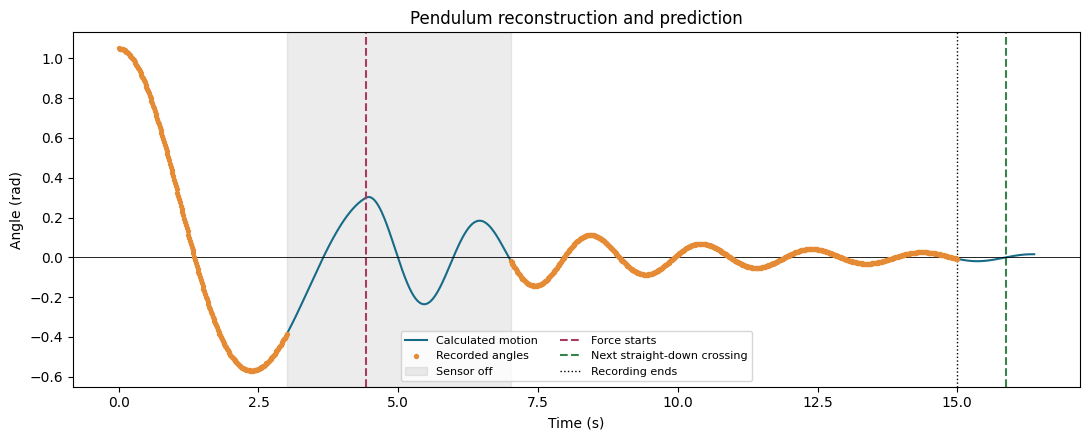

I estimate that the force started at **4.4187 seconds**, which falls inside the sensor gap, and that the pendulum next passes straight down at **15.8764 seconds**, after recording ends at **15.0000 seconds**.

In [11]:
data = main_result['data']
t, theta = data['t'], data['theta']
forecast_times = np.linspace(0, main_row['t_nextzerotheta'] + 0.5, 2000)
forecast_angles = integrate_motion(main_result['parameters'], forecast_times, 0.005)[:, 0]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(forecast_times, forecast_angles, color='#176b87', lw=1.5, label='Calculated motion')
ax.scatter(t, theta, color='#e58b35', s=8, label='Recorded angles', zorder=3)
ax.axvspan(*data['gap'], color='grey', alpha=0.15, label='Sensor off')
ax.axvline(main_row['t_Fput'], color='#a93a62', ls='--', label='Force starts')
ax.axvline(main_row['t_nextzerotheta'], color='#38834a', ls='--', label='Next straight-down crossing')
ax.axvline(t[-1], color='black', ls=':', lw=1, label='Recording ends')
ax.axhline(0, color='black', lw=0.6)
ax.set(xlabel='Time (s)', ylabel='Angle (rad)', title='Pendulum reconstruction and prediction')
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

display(Markdown(
    f"I estimate that the force started at **{main_row['t_Fput']:.4f} seconds**, which falls "
    f"inside the sensor gap, and that the pendulum next passes straight down at "
    f"**{main_row['t_nextzerotheta']:.4f} seconds**, after recording ends at **{t[-1]:.4f} seconds**."
))


# 7. Save the submissions

I put the five answers into the required column order and save one row for each supplied dataset so the CSV contains the values that the competition expects to read. Also note that only the training input is available locally, so the messages about missing Test A and Test B reflect which files the notebook can currently read. 

In [12]:
SUBMISSION_COLUMNS = ['l', 'miu', 'F', 't_nextzerotheta', 't_Fput']


def export_submissions(paths, output_dir, training_result):
    for name, input_path in paths.items():
        if input_path is None:
            print(f'{INPUT_FILENAMES[name]} is not supplied; no submission generated for it.')
            continue
        result = (training_result if name == 'train' else
                  fit_pendulum(pd.read_csv(input_path), starts=settings.starts,
                               max_iter=settings.max_iter))
        try:
            row = submission_row(result)
        except ValueError:
            alpha, beta1, beta2, _, force_time = result['parameters']
            length = 9.8 / beta1
            row = {'l': length, 'miu': alpha, 'F': length * (beta2 - beta1),
                   't_nextzerotheta': 1.0, 't_Fput': force_time}
            print('No future crossing found; using the allowed default 1 for that field.')
        output = pd.DataFrame([row], columns=SUBMISSION_COLUMNS)
        assert output.shape == (1, 5) and np.isfinite(output.to_numpy()).all()
        output.to_csv(Path(output_dir) / OUTPUT_FILENAMES[name], index=False, float_format='%.10f')
        print('Saved:', OUTPUT_FILENAMES[name])


export_submissions(input_paths, OUTPUT_DIR, main_result)


Saved: submission_train.csv
pendulum_testA.csv is not supplied; no submission generated for it.
pendulum_testB.csv is not supplied; no submission generated for it.


## Checking predictions on withheld measurements

I withhold the final 20% of the recorded observations after the sensor gap, fit the same method using the earlier observations, and then predict the withheld angles. I compare the prediction error with a baseline that always predicts zero, because the later swings are small and a low error alone could be misleading.

This checks whether the fitted equation can predict later measurements, although it does not directly verify the unknown physical parameters or determine the official competition score.

In [13]:
check_data = prepare_data(training_frame)

post_gap_count = len(check_data['t']) - check_data['split']
held_count = int(np.ceil(0.20 * post_gap_count))
cut = len(check_data['t']) - held_count

check_result = fit_pendulum(
    check_data['frame'].iloc[:cut].copy(),
    starts=settings.starts,
    max_iter=settings.max_iter,
)

held_times = check_data['t'][cut:]
held_angles = check_data['theta'][cut:]

held_predictions = integrate_motion(
    check_result['parameters'],
    held_times,
    0.005,
)[:, 0]

errors = held_predictions - held_angles

print('Observations excluded from this fit:', held_count)

display(pd.DataFrame({
    'Measure': [
        'Prediction RMSE (radians)',
        'Prediction MAE (radians)',
        'Always-zero baseline RMSE (radians)',
    ],
    'Value': [
        float(np.sqrt(np.mean(errors**2))),
        float(np.mean(np.abs(errors))),
        float(np.sqrt(np.mean(held_angles**2))),
    ],
}))

Observations excluded from this fit: 107


,Measure,Value
0,Prediction RMSE (radians),0.000077
1,Prediction MAE (radians),0.000067
2,Always-zero baseline RMSE (radians),0.018749


In [14]:
elapsed_seconds = perf_counter() - NOTEBOOK_START
print(
    f'Measured notebook runtime for this run: '
    f'{elapsed_seconds:.2f} seconds'
)

Measured notebook runtime for this run: 19.38 seconds


# 8. Conclusion

I used the recorded angles and the supplied pendulum equation to estimate the values below then eventually used that fitted equation to calculate the motion through the sensor gap and continue it beyond the end of the recording. This gives me estimates for both the physical setup and the two requested times which I can check against the interval where the sensor was off and the time when recording ended.

| Quantity | CSV column | Estimated value |
| --- | --- | ---: |
| Rope length | `l` | 4.899292 |
| Air resistance coefficient | `miu` | 0.501712 |
| Added downward force | `F` | 39.990233 |
| Time when the force started | `t_Fput` | 4.418689 seconds |
| Next straight-down crossing after recording ends | `t_nextzerotheta` | 15.876415 seconds |

I estimate that the force began inside the observed gap and that the next straight-down crossing occurs after recording ends at 15 seconds while the fitted angles have an RMSE of approximately **0.000379605 radians** across the recorded observations.